In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import os
os.chdir("/Users/lior/DS6021/DS6021_F26/data")

fram = pd.read_csv("framingham.csv").dropna()
y = fram["TenYearCHD"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_model(numeric_col):
    pre = ColumnTransformer(transformers=[
        ("binary", "passthrough", ["male"]),
        ("numeric", StandardScaler(), [numeric_col]),
    ])
    return Pipeline([("pre", pre), ("lr", LogisticRegression())])

features = {"Model A": ["male", "age"], "Model B": ["male", "cigsPerDay"]}
models = {"Model A": make_model("age"), "Model B": make_model("cigsPerDay")}

#used claude to clean and help with code

In [3]:
p = y.mean()
print("a) fraction with CHD:", round(p, 4))
print("b) accuracy of always predicting no CHD:", round(1 - p, 4))
print("c) log loss of constant probability p:", round(log_loss(y, np.full(len(y), p)), 4))

a) fraction with CHD: 0.1523
b) accuracy of always predicting no CHD: 0.8477
c) log loss of constant probability p: 0.4266


1a

15.23 percent 

1b

84.77%

1c

log loss = 0.4266

In [4]:
probs = {}
for name, m in models.items():
    m.fit(fram[features[name]], y)
    probs[name] = m.predict_proba(fram[features[name]])[:, 1]
    print(name, "sklearn log loss:", round(log_loss(y, probs[name]), 4))

pa = probs["Model A"]
by_hand = -np.mean(y * np.log(pa) + (1 - y) * np.log(1 - pa))
print("Model A by hand:", round(by_hand, 4))

Model A sklearn log loss: 0.3942
Model B sklearn log loss: 0.4222
Model A by hand: 0.3942


In [ ]:
#3a
rows = {}
for name, m in models.items():
    r = cross_validate(m, fram[features[name]], y, cv=cv,
                       scoring=["accuracy", "neg_log_loss", "roc_auc"])
    rows[name] = {
        "accuracy": f"{r['test_accuracy'].mean():.4f} ± {r['test_accuracy'].std():.4f}",
        "log_loss": f"{-r['test_neg_log_loss'].mean():.4f} ± {r['test_neg_log_loss'].std():.4f}",
        "roc_auc":  f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}",
    }
pd.DataFrame(rows).T

,accuracy,log_loss,roc_auc
Model A,0.8480 ± 0.0010,0.3953 ± 0.0134,0.7013 ± 0.0396
Model B,0.8477 ± 0.0006,0.4233 ± 0.0023,0.5645 ± 0.0319


3b
both models accuracy is equal to the 84.8% baseline of predicting no cdh for everyone and you cant tell the two models apart by accuracy so its not the most useful because the classes arent equal and at a 0.5 percent threshold none of the models predict chd, so they score the same as the model that doesnt do anything even though one is better at ranking risk




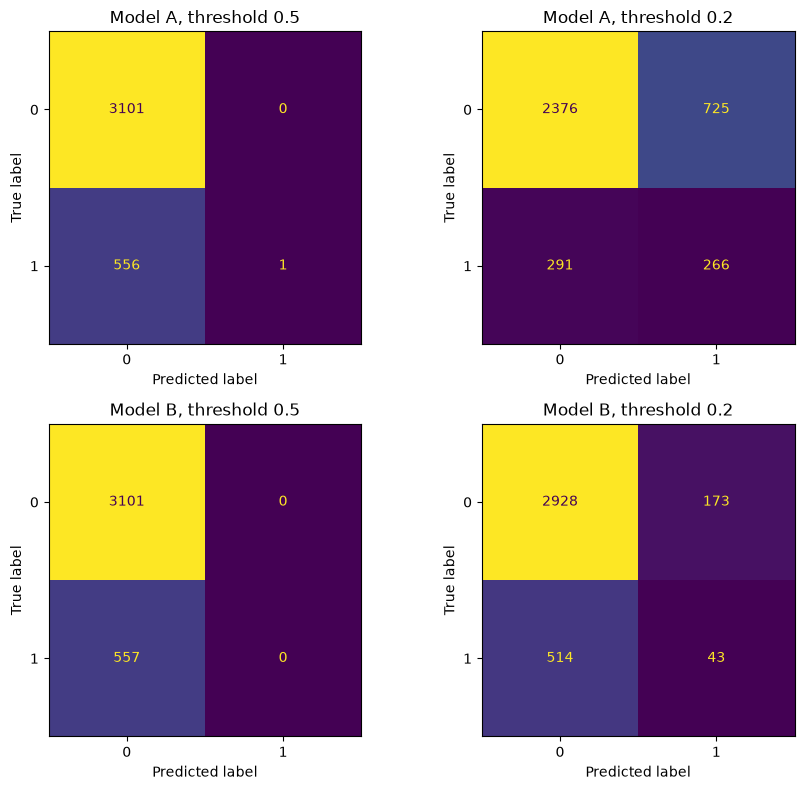

In [6]:
oof = {n: cross_val_predict(m, fram[features[n]], y, cv=cv, method="predict_proba")[:, 1]
       for n, m in models.items()}
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for i, name in enumerate(models):
    for j, t in enumerate([0.5, 0.2]):
        ConfusionMatrixDisplay.from_predictions(y, oof[name] >= t, ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f"{name}, threshold {t}")
plt.tight_layout(); plt.show()

3c

at 0.5 both of the models basically predict no chd other than the one case in model a which is why the accuracy is the same as the baseline. at 0.2 te models start flagging patients where model a cathes 266 chd cases and model b only catches 43. lowering the threshold seems to favor sensitivity over accuracy and model A is better suited for it

3d

model a because it has a lower cv lof loss and a higher auc and a more useful matrix at the smaller threshold while model b barely improves on anything . model a cuts log loss by 0.03.